# 05 — Bordas, gradientes e morfologia matemática

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 05/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 05/16

> **Execução:** ainda não confirmada nesta versão; reinicie o kernel e execute as células obrigatórias localmente.


### Materiais complementares

- [Guia Técnico](./reference_materials/05_bordas_gradientes_morfologia.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_bordas_gradientes_morfologia.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Aplicar Sobel, Canny, dilatação e erosão e explicar seus efeitos.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Bordas são descontinuidades de intensidade. Sobel aproxima derivadas em x e y; Canny incorpora suavização, supressão de não máximos e limiares. Dilatação expande componentes de uma máscara; erosão encolhe. Abertura remove pontos pequenos e fechamento preenche lacunas conforme elemento estruturante.

### Conceito matemático

$$\|\nabla I\|=\sqrt{G_x^2+G_y^2}$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
from skimage.data import coins
from skimage.filters import sobel,threshold_otsu
from skimage.feature import canny
from skimage.morphology import opening,closing,disk
im=coins()/255
edge=sobel(im);can=canny(im,sigma=1.5);mask=im>threshold_otsu(im)
opened=opening(mask,footprint=disk(2));closed=closing(opened,footprint=disk(3))
print('píxeis Canny:',int(can.sum()),'máscara antes/depois:',int(mask.sum()),int(closed.sum()))

píxeis Canny: 8919 máscara antes/depois: 45621 45446


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

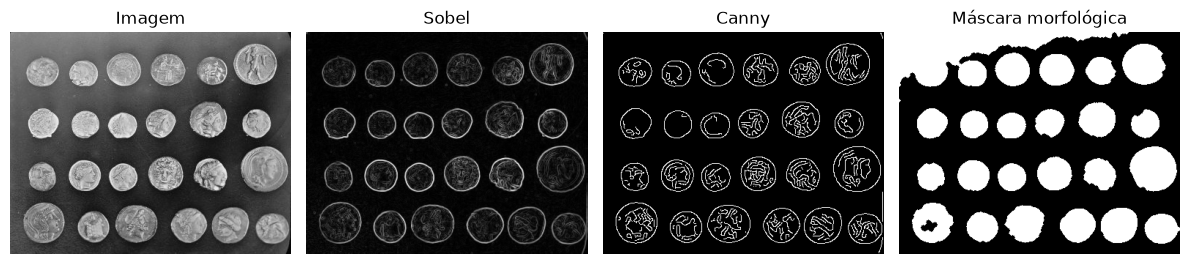

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,4,figsize=(12,3))
for a,t,v in zip(ax,['Imagem','Sobel','Canny','Máscara morfológica'],[im,edge,can,closed]):a.imshow(v,cmap='gray');a.set_title(t);a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

Gradiente estima variação local, mas não identifica automaticamente objetos.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Abertura morfológica é erosão seguida de quê?

**Resolução comentada:** Dilatação com o mesmo elemento estruturante.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

O resultado morfológico depende da escala do elemento estruturante.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Aplicar Sobel, Canny, dilatação e erosão e explicar seus efeitos.
- **Mecanismo:** Bordas são descontinuidades de intensidade.
- **Equação:** $\|\nabla I\|=\sqrt{G_x^2+G_y^2}$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** limiar de borda. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **limiar de borda** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Laboratório adicional — Gradiente Sobel com imagem sintética

Experimento independente do estado das células anteriores. Use-o como verificação e explique seus limites; resultados em conjuntos sintéticos não são estimativas de desempenho real.

In [3]:
import numpy as np
from skimage.filters import sobel
img=np.zeros((20,20),dtype=float);img[:,10:]=1
res=sobel(img)
print('Máximo do gradiente:',round(float(res.max()),3),'coluna predominante:',int(np.argmax(res.mean(axis=0))))

Máximo do gradiente: 0.707 coluna predominante: 9


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **limiar de borda** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
